# TUGAS 3 — PRAKTIK DAN PENGEMBANGAN AI RECIPE UNTUK GEOFISIKA

**Nama:** Eirene Meilona Rappun  
**NIM:** H061251081  
**Mata Kuliah:** Kecerdasan Artifisial Geofisika

---

## Pendahuluan

AI Recipe merupakan panduan kerja terstruktur untuk menyelesaikan suatu permasalahan menggunakan bantuan kecerdasan artifisial.

Pada tugas ini dilakukan praktik recipe dari buku *AI Cookbook untuk Earth Sciences* serta pengembangan recipe baru yang berkaitan dengan bidang geofisika.

Tujuan tugas ini adalah memahami penyusunan recipe, penerapan kode Python, pemeriksaan hasil, dan dokumentasi proses analisis.

# BAGIAN I — RECIPE DARI BUKU

## Recipe 1: Audit Station CSV (R-IO-001)

### A. Problem


Recipe ini bertujuan memeriksa kualitas data pengamatan stasiun dalam format CSV sebelum digunakan untuk analisis lebih lanjut.

Pemeriksaan dilakukan terhadap struktur kolom, nilai kosong, rentang waktu pengamatan, dan timestamp duplikat.

### B. Minimal Theory

Quality Assurance dan Quality Control (QA/QC) merupakan proses pemeriksaan kualitas data untuk mengidentifikasi kesalahan atau ketidaksesuaian.

Dalam pengolahan data geofisika, pemeriksaan kualitas data penting dilakukan agar kesalahan pada data tidak memengaruhi hasil analisis.

### C. Input dan Constraints

**Input:**
- File CSV: `station-example.csv`
- Kolom waktu: `time`
- Kolom stasiun: `station_id`
- Kolom temperatur: `temperature_c`
- Kolom curah hujan: `rainfall_mm`

**Constraints:**
- File sumber tidak boleh diubah.
- Nilai kosong dan timestamp duplikat harus dilaporkan.
- Pemeriksaan dibatasi pada kualitas data dan statistik deskriptif.

### D. Prompt dan Procedure

**Prompt dokumentasi:**

> Buat recipe untuk melakukan audit kualitas data CSV stasiun pengamatan menggunakan Python dan pandas. Periksa jumlah baris dan kolom, tipe data, nilai kosong, rentang waktu, timestamp duplikat, serta statistik deskriptif. Jangan mengubah data sumber dan sajikan hasil pemeriksaan dalam laporan Markdown.

*Prompt di atas merupakan rumusan dokumentasi praktik, bukan kutipan langsung dari buku.*

**Procedure:**

1. Membaca data CSV menggunakan Python.
2. Memeriksa struktur dan tipe data setiap kolom.
3. Mengidentifikasi nilai yang hilang.
4. Memeriksa rentang waktu pengamatan.
5. Mengidentifikasi timestamp duplikat.
6. Menghitung statistik deskriptif.
7. Menampilkan hasil pemeriksaan.

### E. Code / Implementation

Recipe ini menggunakan program `r-io-001.py` dari bahan pendamping buku *AI Cookbook untuk Earth Sciences*.

Program asli telah berhasil dijalankan melalui terminal VS Code menggunakan Python 3.13.11 dan pandas 3.0.0.

Pada notebook ini dilakukan pemeriksaan ulang terhadap data contoh yang sama untuk menampilkan hasil analisis secara langsung.

In [1]:
import pandas as pd
from io import StringIO

# Data contoh dari recipe R-IO-001
data_csv = """time,station_id,temperature_c,rainfall_mm
2026-01-01T00:00:00Z,STA001,25.2,0.0
2026-01-01T01:00:00Z,STA001,24.8,0.0
2026-01-01T02:00:00Z,STA001,,1.2
2026-01-01T02:00:00Z,STA001,24.1,1.1
2026-01-01T04:00:00Z,STA001,23.7,0.3
"""

# Membaca data CSV
data = pd.read_csv(StringIO(data_csv))

# Menampilkan tabel
display(data)

,time,station_id,temperature_c,rainfall_mm
0,2026-01-01T00:00:00Z,STA001,25.2,0.0
1,2026-01-01T01:00:00Z,STA001,24.8,0.0
2,2026-01-01T02:00:00Z,STA001,NaN,1.2
3,2026-01-01T02:00:00Z,STA001,24.1,1.1
4,2026-01-01T04:00:00Z,STA001,23.7,0.3


In [2]:
# Pemeriksaan kualitas data stasiun

print("HASIL AUDIT DATA STASIUN")
print("-------------------------")

print("Jumlah baris:", len(data))
print("Jumlah kolom:", len(data.columns))
print("Jumlah stasiun unik:", data["station_id"].nunique())

print("\nNilai kosong setiap kolom:")
print(data.isna().sum())

print("\nTimestamp duplikat:", data["time"].duplicated().sum())

print("\nStatistik deskriptif:")
display(data[["temperature_c", "rainfall_mm"]].describe())

HASIL AUDIT DATA STASIUN
-------------------------
Jumlah baris: 5
Jumlah kolom: 4
Jumlah stasiun unik: 1

Nilai kosong setiap kolom:
time             0
station_id       0
temperature_c    1
rainfall_mm      0
dtype: int64

Timestamp duplikat: 1

Statistik deskriptif:


,temperature_c,rainfall_mm
count,4.000000,5.000000
mean,24.450000,0.520000
std,0.675771,0.589067
min,23.700000,0.000000
25%,24.000000,0.000000
50%,24.450000,0.300000
75%,24.900000,1.100000
max,25.200000,1.200000


### F. Result

Recipe R-IO-001 berhasil dijalankan menggunakan Python dan pandas.

Hasil pemeriksaan data CSV menunjukkan:

| Parameter | Hasil |
|---|---|
| Jumlah baris | 5 |
| Jumlah kolom | 4 |
| Jumlah stasiun unik | 1 |
| Nilai temperatur kosong | 1 |
| Nilai curah hujan kosong | 0 |
| Timestamp duplikat | 1 |
| Rata-rata temperatur | 24,45 °C |
| Rata-rata curah hujan | 0,52 mm |

Program asli dari buku juga telah menghasilkan laporan `station-summary.md`.

### G. Optional Check / Evidence

Hasil pemeriksaan menunjukkan bahwa jumlah baris dan kolom sesuai dengan data sumber.

Ditemukan satu nilai temperatur kosong dan satu timestamp duplikat. Nilai rata-rata temperatur dihitung dari empat pengamatan valid, sedangkan rata-rata curah hujan dihitung dari lima pengamatan.

**Kesimpulan Recipe 1:**

Recipe Audit Station CSV berhasil digunakan untuk memeriksa kualitas data pengamatan stasiun. Hasil menunjukkan bahwa data masih memiliki nilai kosong dan timestamp duplikat yang perlu diperhatikan sebelum dilakukan analisis lebih lanjut.

**Status Eksekusi: Executed — Berhasil.**

---

# BAGIAN II — RECIPE BUATAN SENDIRI

## Recipe 2: Analisis Gradien Geotermal (R-GEO-001)

### A. Problem

Gradien geotermal merupakan perubahan temperatur bumi terhadap kedalaman. Analisis gradien geotermal dapat digunakan untuk memahami bagaimana temperatur meningkat seiring bertambahnya kedalaman.

Recipe ini bertujuan menghitung gradien geotermal berdasarkan data kedalaman dan temperatur, kemudian menampilkan hubungan keduanya dalam bentuk grafik menggunakan Python.

### B. Minimal Theory

Gradien geotermal adalah laju perubahan temperatur terhadap kedalaman yang umumnya dinyatakan dalam °C/km.

Secara sederhana, gradien geotermal dihitung menggunakan persamaan:

$$
G = \frac{\Delta T}{\Delta z}
$$

dengan:

- $G$ = gradien geotermal (°C/km)
- $\Delta T$ = perubahan temperatur (°C)
- $\Delta z$ = perubahan kedalaman (km)

Gradien geotermal positif menunjukkan bahwa temperatur meningkat seiring bertambahnya kedalaman.

### C. Input dan Constraints

**Input:**

Data kedalaman dan temperatur sintetis berikut:

| Kedalaman (m) | Temperatur (°C) |
|---|---|
| 0 | 27 |
| 100 | 30 |
| 200 | 33 |
| 300 | 36 |
| 400 | 39 |

**Constraints:**

- Data yang digunakan merupakan data sintetis untuk demonstrasi, bukan hasil pengukuran lapangan.
- Kedalaman dinyatakan dalam meter dan dikonversi menjadi kilometer saat menghitung gradien.
- Temperatur dinyatakan dalam derajat Celsius.
- Analisis mengasumsikan hubungan temperatur dan kedalaman bersifat linear.
- Hasil tidak digunakan untuk menyimpulkan kondisi geotermal suatu wilayah nyata.

### D. Prompt dan Procedure

**Prompt AI:**

> Buat program Python untuk menghitung gradien geotermal berdasarkan data kedalaman dan temperatur. Gunakan pandas untuk mengolah data, numpy untuk menghitung gradien, dan matplotlib untuk membuat grafik hubungan temperatur terhadap kedalaman. Nyatakan satuan dengan jelas, gunakan data sintetis, dan tampilkan hasil perhitungan dalam °C/km. Tambahkan pemeriksaan sederhana untuk memastikan hasil perhitungan sesuai dengan rumus gradien geotermal.

**Procedure:**

1. Menyiapkan data kedalaman dan temperatur.
2. Membaca data menggunakan pandas.
3. Mengonversi kedalaman dari meter menjadi kilometer.
4. Menghitung gradien geotermal menggunakan numpy.
5. Menampilkan hasil perhitungan.
6. Membuat grafik hubungan temperatur dan kedalaman.
7. Memeriksa hasil menggunakan perhitungan manual.

### E. Code / Implementation

Implementasi dilakukan menggunakan Python dengan library:

- `pandas` untuk menyusun data.
- `numpy` untuk menghitung gradien geotermal.
- `matplotlib` untuk membuat grafik.

Program menggunakan data sintetis agar hasil perhitungan dapat diperiksa dengan mudah.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data sintetis kedalaman dan temperatur
kedalaman = [0, 100, 200, 300, 400]
temperatur = [27, 30, 33, 36, 39]

# Membuat tabel data
data_geo = pd.DataFrame({
    "Kedalaman (m)": kedalaman,
    "Temperatur (°C)": temperatur
})

# Mengonversi kedalaman menjadi kilometer
kedalaman_km = np.array(kedalaman) / 1000

# Menghitung gradien geotermal
gradien = np.polyfit(kedalaman_km, temperatur, 1)[0]

print("HASIL ANALISIS GRADIEN GEOTERMAL")
print("--------------------------------")
print(f"Gradien geotermal = {gradien:.2f} °C/km")

display(data_geo)

HASIL ANALISIS GRADIEN GEOTERMAL
--------------------------------
Gradien geotermal = 30.00 °C/km


,Kedalaman (m),Temperatur (°C)
0,0,27
1,100,30
2,200,33
3,300,36
4,400,39


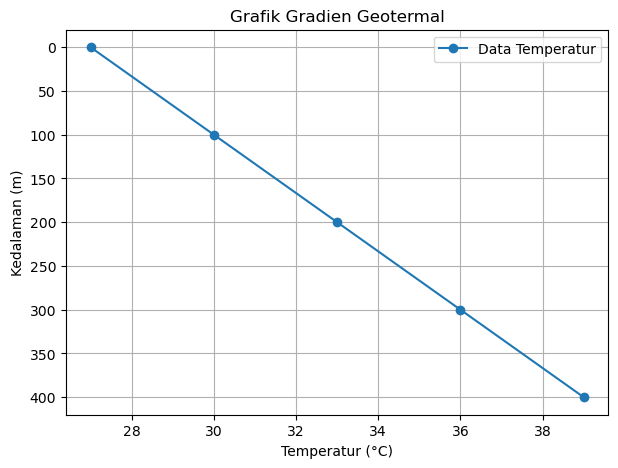

In [4]:
# Membuat grafik temperatur terhadap kedalaman
plt.figure(figsize=(7, 5))

plt.plot(
    temperatur,
    kedalaman,
    marker="o",
    linestyle="-",
    label="Data Temperatur"
)

# Kedalaman bertambah ke arah bawah
plt.gca().invert_yaxis()

plt.xlabel("Temperatur (°C)")
plt.ylabel("Kedalaman (m)")
plt.title("Grafik Gradien Geotermal")
plt.grid(True)
plt.legend()

plt.show()

In [5]:
# Pemeriksaan hasil menggunakan rumus manual

T_awal = 27
T_akhir = 39

z_awal = 0
z_akhir = 400

# Menghitung perubahan temperatur dan kedalaman
delta_T = T_akhir - T_awal
delta_z = (z_akhir - z_awal) / 1000

# Gradien manual
gradien_manual = delta_T / delta_z

print("PEMERIKSAAN HASIL")
print("-----------------")
print(f"Gradien Python = {gradien:.2f} °C/km")
print(f"Gradien Manual = {gradien_manual:.2f} °C/km")

# Memeriksa kesesuaian hasil
assert np.isclose(gradien, gradien_manual)

print("Hasil perhitungan sesuai.")

PEMERIKSAAN HASIL
-----------------
Gradien Python = 30.00 °C/km
Gradien Manual = 30.00 °C/km
Hasil perhitungan sesuai.


### F. Result

Program analisis gradien geotermal dijalankan menggunakan Python dengan data kedalaman dan temperatur sintetis.

Berdasarkan hasil perhitungan, diperoleh:

| Parameter | Hasil |
|---|---|
| Kedalaman minimum | 0 m |
| Kedalaman maksimum | 400 m |
| Temperatur minimum | 27 °C |
| Temperatur maksimum | 39 °C |
| Perubahan temperatur | 12 °C |
| Perubahan kedalaman | 0,4 km |
| Gradien geotermal | 30 °C/km |

Hasil menunjukkan bahwa temperatur meningkat sebesar 30 °C untuk setiap pertambahan kedalaman 1 km berdasarkan hubungan linear pada data sintetis yang digunakan.

Grafik memperlihatkan peningkatan temperatur seiring bertambahnya kedalaman.

### G. Optional Check / Evidence

Pemeriksaan dilakukan dengan membandingkan hasil perhitungan Python dan perhitungan manual.

Secara manual:

$$
G = \frac{\Delta T}{\Delta z}
$$

$$
G = \frac{39-27}{0,4}
$$

$$
G = 30\ ^\circ C/km
$$

Hasil perhitungan manual sesuai dengan hasil program Python, yaitu 30 °C/km.

**Kesimpulan Recipe 2:**

Recipe Analisis Gradien Geotermal berhasil digunakan untuk menghitung perubahan temperatur terhadap kedalaman menggunakan Python.

Berdasarkan data sintetis, diperoleh gradien geotermal sebesar 30 °C/km. Hasil perhitungan telah diperiksa menggunakan rumus manual dan menunjukkan nilai yang sesuai.

Hasil ini merupakan demonstrasi perhitungan dan tidak mewakili kondisi geotermal wilayah tertentu.

**Status Eksekusi: Executed — Berhasil.**

---

# KESIMPULAN AKHIR

Berdasarkan pelaksanaan kedua recipe, dapat disimpulkan bahwa:

1. Recipe Audit Station CSV dari buku *AI Cookbook untuk Earth Sciences* berhasil digunakan untuk memeriksa kualitas data pengamatan stasiun. Hasil pemeriksaan menemukan satu nilai temperatur kosong dan satu timestamp duplikat.

2. Recipe Analisis Gradien Geotermal yang dikembangkan sendiri berhasil digunakan untuk menghitung gradien temperatur terhadap kedalaman menggunakan Python. Berdasarkan data sintetis, diperoleh gradien geotermal sebesar 30 °C/km.

3. Kedua recipe menunjukkan bahwa Python dapat digunakan untuk membantu proses pemeriksaan data, perhitungan, visualisasi, dan verifikasi sederhana dalam bidang geofisika.

Melalui tugas ini, konsep AI Recipe diterapkan dalam bentuk alur kerja yang terstruktur, mulai dari identifikasi masalah, penyusunan prompt, implementasi kode, hingga pemeriksaan hasil.